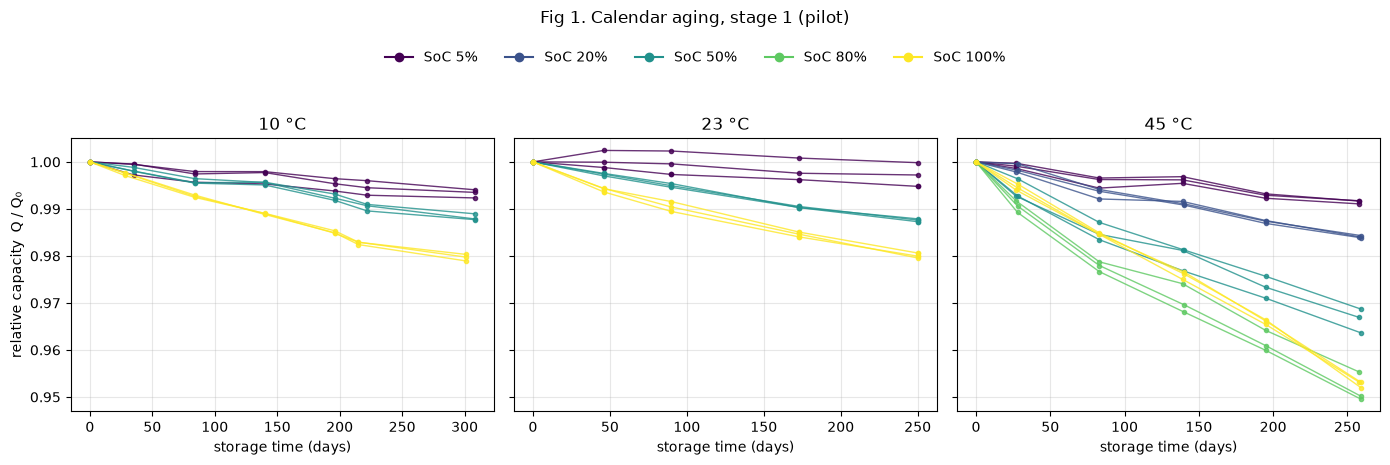

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# figure 1: calendar aging
cap = pd.read_parquet("../data/processed/capacity_rpt.parquet")            # the table you just built (loads in about a second)
d = cap[(cap["type"] == "k") & (cap["stage"] == 1)                        # calendar cells, stage 1 only
        & cap["kind"].isin(["CU", "exCU"])                                 # regular check-ups only (skip entry/end tests, which use a different protocol)
        & (cap["n_dis_rows"] > 0)].copy()                                  # drop the few tests with no capacity discharge
d = d.sort_values(["cell_id", "date"])
d["days"] = (d["date"] - d.groupby("cell_id")["date"].transform("min")).dt.days   # days since each cell's first check-up
d["Q_rel"] = d["Q_Ah"] / d.groupby("cell_id")["Q_Ah"].transform("first")   # capacity relative to that first check-up (1.0 = no fade)

temps = sorted(d["amb_temp_tp"].unique())                                  # 10, 23, 45 °C
socs = sorted(d["soc_max_tp"].unique())                                    # storage SoC levels
cmap = plt.get_cmap("viridis", len(socs))                                  # one color per SoC: dark = low, yellow = high

fig, axes = plt.subplots(1, len(temps), figsize=(14, 4), sharey=True)      # one panel per temperature, shared y-axis for comparison
for ax, T in zip(axes, temps):
    for cid, g in d[d["amb_temp_tp"] == T].groupby("cell_id"):             # one line per cell
        k = socs.index(g["soc_max_tp"].iloc[0])
        ax.plot(g["days"], g["Q_rel"], "-o", ms=3, lw=1, color=cmap(k), alpha=0.8)
    ax.set_title(f"{T:.0f} °C")
    ax.set_xlabel("storage time (days)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("relative capacity  Q / Q₀")

handles = [plt.Line2D([], [], color=cmap(i), marker="o", label=f"SoC {s:.0%}") for i, s in enumerate(socs)]   # legend: one entry per SoC
fig.legend(handles=handles, loc="upper center", ncol=len(socs), bbox_to_anchor=(0.5, 1.08), frameon=False)
fig.suptitle("Fig 1. Calendar aging, stage 1 (pilot)", y=1.15)
plt.tight_layout()
plt.savefig("../figs/fig1_calendar_s1.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
z = cap[(cap["type"] == "z") & cap["kind"].isin(["CU", "exCU"])]   # cycle cells, regular check-ups
print(z.groupby("cell_id").size().describe())                      # check-ups per cycle cell: min, typical, max
print(sorted(z.columns))                                           # see if any column already measures throughput (Ah or full cycles)

count    147.000000
mean      13.578231
std        4.006716
min        3.000000
25%       11.000000
50%       14.000000
75%       15.000000
max       22.000000
dtype: float64
['Q_Ah', 'R_1khz_0', 'U_0', 'amb_temp_tp', 'c_ch_tp', 'c_dch_tp', 'cell', 'cell_id', 'cu', 'date', 'days', 'dod_tp', 'file_name', 'kind', 'lab', 'm_0', 'n_dis_rows', 'resistance_meter', 'sampling', 'scale', 'soc_max_tp', 'stage', 'tp', 'type', 'volt_meter', 'zip']


In [8]:
# --- Test: read ONE cycling (ZYK) block and compute its charge throughput ---
# Purpose: check the file's format and size, and how long it takes to read, before parsing all ZYK files.

import time
import zipfile

z = zipfile.ZipFile("../data/raw/stroebl/TP_z01_01__47632462.zip")
info = z.getinfo("TP_z01_01/TP_z01_01_02_ZYK.csv")
print("uncompressed MB:", round(info.file_size / 1e6, 1))           # how big one cycling block is

t0 = time.time()
y = pd.read_csv(z.open("TP_z01_01/TP_z01_01_02_ZYK.csv"))           # read the first cycling block
print("read time (s):", round(time.time() - t0, 1), "| rows:", len(y))
print(y.head(3))                                                    # column names and format

y["dt"] = pd.to_timedelta(y["run_time"]).dt.total_seconds().diff().fillna(0)
thr = (y["c_cur"].abs() * y["dt"]).sum() / 3600                     # ∫|I| dt in Ah
print("throughput (Ah):", round(thr, 1), "| EFC:", round(thr / (2 * 4.9), 1))

uncompressed MB: 4.4
read time (s): 0.1 | rows: 65130
       run_time     c_vol  c_cur  c_surf_temp  amb_temp  step_type
0  00:00:00.001  3.704756    0.0    44.867245       NaN         42
1  00:00:00.002  3.704756    0.0    44.867245       NaN         42
2  00:00:00.003  3.704756    0.0    44.867245       NaN         42
throughput (Ah): 827.0 | EFC: 84.4


In [10]:
# --- Compute cumulative throughput (Ah, EFC) at every test of every cycle cell, attach it to cap, save ---
# Self-contained: loads the capacity table from disk. For each cycle zip, sums ∫|I|dt over all
# ZYK (cycling) blocks that come BEFORE each test number → "how much cycling this cell had done by then".
import re
import zipfile
from pathlib import Path
import pandas as pd

RAW = Path("../data/raw/stroebl")                                     # raw zips
PROC = Path("../data/processed/capacity_rpt.parquet")                 # the tidy capacity table built earlier
cap = pd.read_parquet(PROC)

def zyk_throughput(zip_path):
    z = zipfile.ZipFile(zip_path)
    blocks = []
    for name in z.namelist():
        m = re.search(r"_(\d+)_ZYK\.csv$", name)                      # cycling blocks only; capture the sequence number
        if not m:
            continue
        y = pd.read_csv(z.open(name), usecols=["run_time", "c_cur"])
        dt = pd.to_timedelta(y["run_time"]).dt.total_seconds().diff().fillna(0)
        blocks.append({"seq": int(m.group(1)), "Ah": (y["c_cur"].abs() * dt).sum() / 3600})   # ∫|I|dt for this block
    return pd.DataFrame(blocks).sort_values("seq") if blocks else pd.DataFrame(columns=["seq", "Ah"])

cyc_zips = cap.loc[cap["type"] == "z", "zip"].unique()               # the 147 cycle-cell zips
thr_rows = []
for i, zn in enumerate(cyc_zips):
    b = zyk_throughput(RAW / zn)
    for cu in cap.loc[cap["zip"] == zn, "cu"]:                        # for each test of this cell...
        thr_rows.append({"zip": zn, "cu": cu,
                         "thr_Ah": b.loc[b["seq"] < cu, "Ah"].sum()})   # ...sum the cycling done before it
    if i % 25 == 0:
        print(i, zn)

thr = pd.DataFrame(thr_rows)
thr["EFC"] = thr["thr_Ah"] / (2 * 4.9)                                # equivalent full cycles (4.9 Ah nominal)
cap = cap.drop(columns=["thr_Ah", "EFC"], errors="ignore").merge(thr, on=["zip", "cu"], how="left")   # calendar rows get NaN
cap.to_parquet(PROC)

print("cycle rows with throughput:", cap.loc[cap["type"] == "z", "EFC"].notna().sum(), "of", (cap["type"] == "z").sum())
print(cap.loc[cap["type"] == "z"].groupby("cell_id")["EFC"].max().describe().round(0))   # final EFC per cell: range across cells

0 TP_z01_01__47632462.zip
25 TP_z05_01__47632663.zip
50 TP_z09_02__47632429.zip
75 TP_z13_02__47632603.zip
100 TP_z17_03__47632351.zip
125 TP_z21_03__47632636.zip
cycle rows with throughput: 2787 of 2787
count     147.0
mean     1929.0
std      1114.0
min       336.0
25%      1114.0
50%      1628.0
75%      2501.0
max      4888.0
Name: EFC, dtype: float64


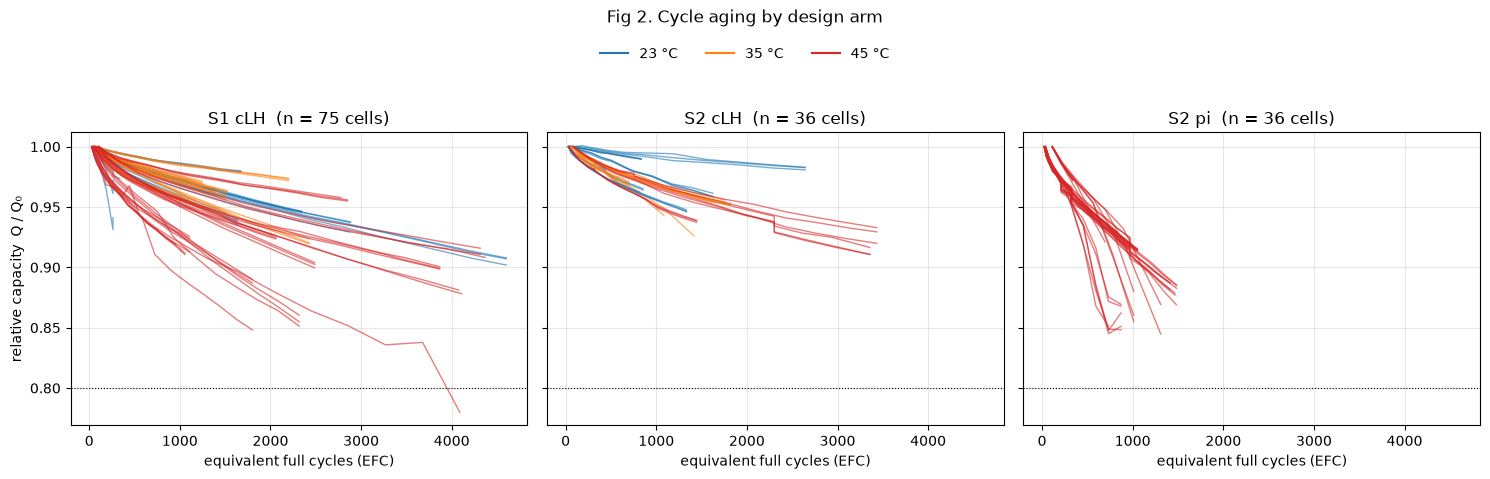

In [1]:
# --- Fig 2: cycle aging — relative capacity vs equivalent full cycles, one panel per arm ---
# Self-contained: loads the capacity table from disk. Uses regular check-ups only (CU, exCU).
# Panels: S1 cLH (pilot), S2 cLH (control), S2 pi (OED). Color = ambient temperature.
import pandas as pd
import matplotlib.pyplot as plt

cap = pd.read_parquet("../data/processed/capacity_rpt.parquet")
d = cap[(cap["type"] == "z") & cap["kind"].isin(["CU", "exCU"]) & (cap["n_dis_rows"] > 0)].copy()
d = d.sort_values(["cell_id", "EFC"])
d["Q_rel"] = d["Q_Ah"] / d.groupby("cell_id")["Q_Ah"].transform("first")   # relative to each cell's first check-up
d["arm"] = "S" + d["stage"].astype(str) + " " + d["sampling"]             # e.g. "S2 pi"

arms = ["S1 cLH", "S2 cLH", "S2 pi"]
tcolor = {23: "tab:blue", 35: "tab:orange", 45: "tab:red"}                # one color per temperature

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True, sharex=True)   # shared axes so the arms are directly comparable
for ax, arm in zip(axes, arms):
    for cid, g in d[d["arm"] == arm].groupby("cell_id"):                 # one line per cell
        ax.plot(g["EFC"], g["Q_rel"], "-", lw=1, alpha=0.6, color=tcolor[g["amb_temp_tp"].iloc[0]])
    n = d.loc[d["arm"] == arm, "cell_id"].nunique()
    ax.set_title(f"{arm}  (n = {n} cells)")
    ax.set_xlabel("equivalent full cycles (EFC)")
    ax.axhline(0.8, color="k", ls=":", lw=0.8)                            # 80% = conventional end of life
    ax.grid(alpha=0.3)
axes[0].set_ylabel("relative capacity  Q / Q₀")

handles = [plt.Line2D([], [], color=c, label=f"{T} °C") for T, c in tcolor.items()]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.07), frameon=False)
fig.suptitle("Fig 2. Cycle aging by design arm", y=1.13)
plt.tight_layout()
plt.savefig("../figs/fig2_cycle_by_arm.png", dpi=200, bbox_inches="tight")
plt.show()

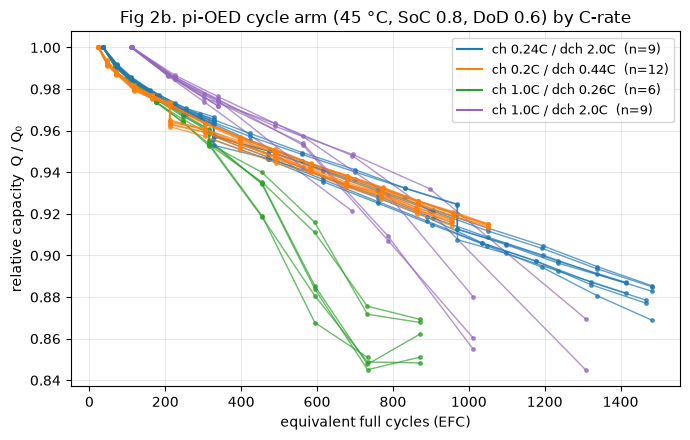

In [2]:
# --- Fig 2b: pi-OED arm only, colored by its 4 C-rate conditions ---
# Self-contained. Tests whether the two groups in the pi arm correspond to different C-rate combinations.
import pandas as pd
import matplotlib.pyplot as plt

cap = pd.read_parquet("../data/processed/capacity_rpt.parquet")
d = cap[(cap["type"] == "z") & (cap["sampling"] == "pi") & cap["kind"].isin(["CU", "exCU"]) & (cap["n_dis_rows"] > 0)].copy()
d = d.sort_values(["cell_id", "EFC"])
d["Q_rel"] = d["Q_Ah"] / d.groupby("cell_id")["Q_Ah"].transform("first")
d["cond"] = "ch " + d["c_ch_tp"].round(2).astype(str) + "C / dch " + d["c_dch_tp"].round(2).astype(str) + "C"   # condition label

conds = sorted(d["cond"].unique())
colors = dict(zip(conds, ["tab:blue", "tab:orange", "tab:green", "tab:purple"]))

fig, ax = plt.subplots(figsize=(7, 4.5))
for cid, g in d.groupby("cell_id"):                                     # one line per cell
    ax.plot(g["EFC"], g["Q_rel"], "-o", ms=2.5, lw=1, alpha=0.7, color=colors[g["cond"].iloc[0]])
for c in conds:
    ax.plot([], [], color=colors[c], label=f"{c}  (n={d.loc[d['cond'] == c, 'cell_id'].nunique()})")   # legend entries with cell counts
ax.set_xlabel("equivalent full cycles (EFC)")
ax.set_ylabel("relative capacity  Q / Q₀")
ax.set_title("Fig 2b. pi-OED cycle arm (45 °C, SoC 0.8, DoD 0.6) by C-rate")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../figs/fig2b_pi_by_crate.png", dpi=200, bbox_inches="tight")
plt.show()

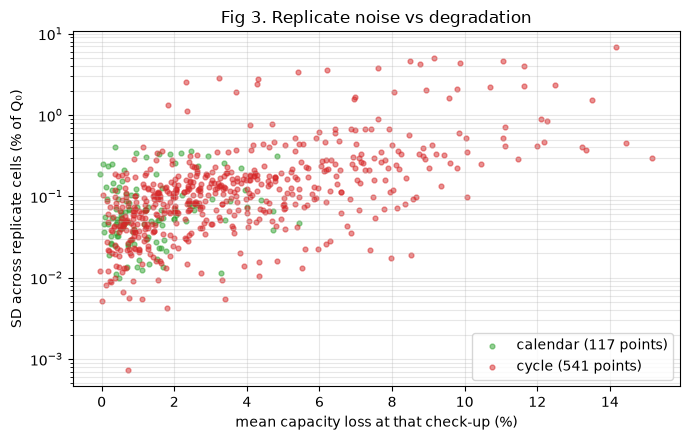

type
k    0.058
z    0.106
Name: median SD (% of Q0), dtype: float64


In [3]:
# --- Fig 3: replicate noise — spread across cells at the same test point vs mean capacity loss ---
# Self-contained. For each test point and each check-up (aligned by its order within each cell),
# compute the mean and SD of Q_rel across replicate cells. Flat SD vs loss = homoscedastic (FIM assumption);
# rising SD = heteroskedastic (D3 diagnostic).
import pandas as pd
import matplotlib.pyplot as plt

cap = pd.read_parquet("../data/processed/capacity_rpt.parquet")
d = cap[cap["kind"].isin(["CU", "exCU"]) & (cap["n_dis_rows"] > 0)].copy()
d = d.sort_values(["cell_id", "date"])
d["Q_rel"] = d["Q_Ah"] / d.groupby("cell_id")["Q_Ah"].transform("first")    # relative to each cell's first check-up
d["k"] = d.groupby("cell_id").cumcount()                                     # check-up order within the cell: 0, 1, 2, …
d["tp_id"] = d["type"] + "_s" + d["stage"].astype(str) + "_" + d["sampling"] + "_" + d["tp"].astype(str)   # unique test point

g = (d[d["k"] > 0]                                                           # skip k = 0, where Q_rel = 1 by construction
       .groupby(["type", "tp_id", "k"])["Q_rel"]
       .agg(mean="mean", sd="std", n="count")
       .reset_index())
g = g[g["n"] >= 3]                                                           # need at least 3 replicates for a meaningful SD
g["loss"] = 1 - g["mean"]                                                    # mean capacity lost at that check-up

fig, ax = plt.subplots(figsize=(7, 4.5))
for t, c, lab in [("k", "tab:green", "calendar"), ("z", "tab:red", "cycle")]:
    s = g[g["type"] == t]
    ax.scatter(s["loss"] * 100, s["sd"] * 100, s=12, alpha=0.5, color=c, label=f"{lab} ({len(s)} points)")
ax.set_xlabel("mean capacity loss at that check-up (%)")
ax.set_ylabel("SD across replicate cells (% of Q₀)")
ax.set_yscale("log")                                                          # log scale: SDs span orders of magnitude
ax.set_title("Fig 3. Replicate noise vs degradation")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.savefig("../figs/fig3_replicate_noise.png", dpi=200, bbox_inches="tight")
plt.show()

print(g.groupby("type")["sd"].median().mul(100).round(3).rename("median SD (% of Q0)"))   # typical replicate noise per sub-study

In [16]:
# --- Diagnose Fig 3's upper band: which test points have replicate SD > 1%? ---
# Self-contained. Recomputes the per-test-point spread and lists the high-spread test points,
# with each replicate cell's number of check-ups (unequal counts would mean misaligned check-ups).
import pandas as pd

cap = pd.read_parquet("../data/processed/capacity_rpt.parquet")
d = cap[cap["kind"].isin(["CU", "exCU"]) & (cap["n_dis_rows"] > 0)].copy().sort_values(["cell_id", "date"])
d["Q_rel"] = d["Q_Ah"] / d.groupby("cell_id")["Q_Ah"].transform("first")
d["k"] = d.groupby("cell_id").cumcount()
d["tp_id"] = d["type"] + "_s" + d["stage"].astype(str) + "_" + d["sampling"] + "_" + d["tp"].astype(str)

sd = d[d["k"] > 0].groupby(["tp_id", "k"])["Q_rel"].std()                   # replicate SD per test point and check-up
high = sd[sd > 0.01].index.get_level_values("tp_id").unique()               # test points that ever exceed 1% SD
print(len(high), "test points with SD > 1%:\n")
print(d[d["tp_id"].isin(high)]
        .groupby(["tp_id", "cell_id"])
        .agg(n_checkups=("k", "size"), last_EFC=("EFC", "max"), last_Qrel=("Q_rel", "last"))
        .round(3))

17 test points with SD > 1%:

                          n_checkups  last_EFC  last_Qrel
tp_id       cell_id                                      
z_s1_cLH_11 TP_z11_01_s1          44  2198.851      0.973
            TP_z11_02_s1          11  2199.026      0.972
            TP_z11_03_s1          11  2198.780      0.974
z_s1_cLH_12 TP_z12_01_s1          11   814.532      0.973
            TP_z12_02_s1          11   814.535      0.975
            TP_z12_03_s1          11   814.839      0.997
z_s1_cLH_13 TP_z13_01_s1          44  1171.874      0.955
            TP_z13_02_s1          11  1170.408      0.953
            TP_z13_03_s1          11  1171.680      0.953
z_s1_cLH_17 TP_z17_01_s1          14  1801.017      0.890
            TP_z17_02_s1          14  1800.700      0.887
            TP_z17_03_s1          14  1800.879      0.848
z_s1_cLH_25 TP_z25_01_s1          14  4088.801      0.966
            TP_z25_02_s1          14  4076.052      0.881
            TP_z25_03_s1          14  4109

In [17]:
# --- Fix: find and drop duplicated test rows in the capacity table ---
# Self-contained. A test is identified by (zip, cu, kind); each should appear once.
# Reports how many duplicates exist, removes them, and re-checks rows per cell.
import pandas as pd

PROC = "../data/processed/capacity_rpt.parquet"
cap = pd.read_parquet(PROC)
key = ["zip", "cu", "kind"]                                                  # one test = one zip + test number + test kind

print("rows before:", len(cap))
print("duplicate tests:", cap.duplicated(subset=key).sum())                  # rows whose key already appeared
print("cells affected:", cap.loc[cap.duplicated(subset=key, keep=False), "cell_id"].nunique())

cap = cap.drop_duplicates(subset=key, keep="first").reset_index(drop=True)   # keep one row per test
print("rows after:", len(cap))
print("checks: max rows per (zip, cu, kind) =", cap.groupby(key).size().max())   # should be 1

cap.to_parquet(PROC)

rows before: 3550
duplicate tests: 784
cells affected: 35
rows after: 2766
checks: max rows per (zip, cu, kind) = 1


In [18]:
# --- Check raw zips for test files that appear more than once ---
# Self-contained. For every zip, counts check-up file names (CU, exCU, ET_T23, AT_T23) that occur
# more than once, and whether those copies have identical sizes.
import re, zipfile
from pathlib import Path
from collections import defaultdict

RAW = Path("../data/raw/stroebl")
report = []
for zp in sorted(RAW.glob("TP_z*.zip")):                                     # cycle zips (where all affected cells are)
    seen = defaultdict(list)
    for info in zipfile.ZipFile(zp).infolist():
        m = re.search(r"_(\d+)_(CU|exCU|ET_T23|AT_T23)\.csv$", info.filename)
        if m:
            key = (int(m.group(1)), m.group(2))                              # (test number, kind)
            seen[key].append((info.filename, info.file_size))
    dups = {k: v for k, v in seen.items() if len(v) > 1}
    if dups:
        same = all(len({s for _, s in v}) == 1 for v in dups.values())       # all copies the same size?
        report.append((zp.name, len(dups), "identical sizes" if same else "DIFFERENT sizes",
                       list(dups.values())[0][:2]))                          # show one example pair

print(len(report), "zips with repeated test files")
for r in report[:8]:
    print(r)

0 zips with repeated test files
